### Importing Libraries and Loading the Dataset
Import the required libraries and load the original dataset for analysis.

In [5]:
# Import required libraries
import pandas as pd 
import numpy as np

# Load the original dataset
df = pd.read_excel("Dirty_Vital_Signs_Analysis_Dataset.xlsx")

# Confirm successful loading
print("Status: Dataset Loaded Successfully!")

Status: Dataset Loaded Successfully!


### 1. Dataset Inspection
Inspect the dataset's dimensions, column names, data types, memory usage, and non-null counts to understand its initial structure.

In [6]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display dataset information
print("\nDataset information:")
df.info()

Dataset shape: (1000, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Patient_ID            1000 non-null   str   
 1   Temperature_C         981 non-null    object
 2   Pulse_Rate_bpm        982 non-null    object
 3   Respiratory_Rate_cpm  982 non-null    object
 4   Systolic_BP_mmHg      982 non-null    object
 5   Diastolic_BP_mmHg     982 non-null    object
 6   Patient_Outcome       1000 non-null   str   
dtypes: object(5), str(2)
memory usage: 68.4+ KB


### 2. Handling Duplicate Records
Identify and remove exact duplicate rows to prevent repeated records from affecting the analysis.

In [7]:
# Check for duplicate rows
print("Check duplicate rows:")
print("Duplicate rows:", df.duplicated().sum())
print()

# Remove duplicate rows
df = df.drop_duplicates()

# Verify duplicate removal
print("Verify duplicates removal:")
print("Duplicate rows:", df.duplicated().sum())
print()

# Check the updated dataset shape
print("Updated dataset shape:", df.shape)

Check duplicate rows:
Duplicate rows: 12

Verify duplicates removal:
Duplicate rows: 0

Updated dataset shape: (988, 7)


### 3. Data Quality and Inconsistency Handling

#### A. Patient_ID

Inspect patient identifiers by checking the number of unique IDs and identifying any duplicate patient IDs to ensure each record has a unique identifier.

In [8]:
## A. Patient_ID Column

# Check unique Patient IDs
print("Unique Patient IDs:", df["Patient_ID"].nunique())

# Check duplicate Patient IDs
print("Duplicate Patient IDs:", df["Patient_ID"].duplicated().sum())
print()

Unique Patient IDs: 988
Duplicate Patient IDs: 0



### 3. Data Quality and Inconsistency Handling

#### B. Temperature_C

Inspect and clean temperature values by identifying and removing unwanted text, converting the column to numeric format, and replacing implausible readings with missing values based on the acceptable range of 35.0–40.5°C.

In [9]:
## B. Temperature_C

# Store the original temperature values
temperature_values = df["Temperature_C"]

# Convert temperature values to numeric for inspection
numeric_temperatures = pd.to_numeric(temperature_values, errors="coerce")

# Select temperature values that could not be converted but were not originally missing
text_temperatures = temperature_values[numeric_temperatures.isna() & temperature_values.notna()]

# Display the unique values containing unwanted text
print("Unique temperature values containing unwanted text:")
print(text_temperatures.unique())

# Remove unwanted characters
df["Temperature_C"] = temperature_values.astype(str).str.strip(" °C")

# Convert temperature values to numeric
df["Temperature_C"] = pd.to_numeric(df["Temperature_C"], errors="coerce")

# Replace implausible temperature values with NaN (Acceptable range: 35.0–40.5°C)
df["Temperature_C"] = df["Temperature_C"].replace([0, 3.8, 48.7, 52], np.nan)
print()

# Check the cleaned temperature distribution
print("Temperature distribution after cleaning:")
print(df["Temperature_C"].describe())

Unique temperature values containing unwanted text:
['35.4 °C' '37.8 °C' '36.4 °C' '36.1 °C' '37.5 °C' '36.5 °C' '36.7 °C'
 '36.0 °C' '36.3 °C' '36.9 °C' '38.0 °C' '37.3 °C' '37.4 °C' '37.0 °C'
 '35.5 °C' '37.2 °C' '37.1 °C' '36.8 °C' '37.7 °C' '38.3 °C' '36.6 °C'
 '35.9 °C' '35.8 °C' '37.6 °C' '37.9 °C']

Temperature distribution after cleaning:
count    966.000000
mean      36.973395
std        0.708254
min       35.000000
25%       36.500000
50%       37.000000
75%       37.500000
max       39.000000
Name: Temperature_C, dtype: float64


### 3. Data Quality and Inconsistency Handling

#### C. Pulse_Rate_bpm

Inspect and clean pulse rate values by identifying and removing unwanted text, converting the column to numeric format, and replacing implausible readings with missing values based on the acceptable range of 45-165bpm.

In [10]:
## C. Pulse_Rate_bpm
# Store the original pulse rate values
pulse_values = df["Pulse_Rate_bpm"]

# Convert pulse rate values to numeric for inspection
numeric_pulse = pd.to_numeric(pulse_values, errors="coerce")

# Select pulse rate values that could not be converted but were not originally missing
text_pulse = pulse_values[numeric_pulse.isna() & pulse_values.notna()]

# Display the unique values containing unwanted text
print("Unique pulse rate values containing unwanted text:")
print(text_pulse.unique())

# Remove unwanted characters
df["Pulse_Rate_bpm"] = pulse_values.astype(str).str.strip(" bpm")

# Convert pulse rate values to numeric
df["Pulse_Rate_bpm"] = pd.to_numeric(df["Pulse_Rate_bpm"], errors="coerce")

# Replace implausible pulse rate values with NaN (Acceptable range: 45–165 bpm)
df["Pulse_Rate_bpm"] = df["Pulse_Rate_bpm"].replace([0, 8, 290, 320], np.nan)
print()

# Check the cleaned pulse rate distribution
print("Pulse rate distribution after cleaning:")
print(df["Pulse_Rate_bpm"].describe())

Unique pulse rate values containing unwanted text:
['122 bpm' '91 bpm' '116 bpm' '117 bpm' '121 bpm' '92 bpm' '109 bpm'
 '54 bpm' '77 bpm' '62 bpm' '98 bpm' '106 bpm' '45 bpm' '108 bpm' '96 bpm'
 '78 bpm' '85 bpm' '58 bpm' '75 bpm' '95 bpm' '87 bpm' '81 bpm' '97 bpm'
 '67 bpm' '129 bpm' '73 bpm' '49 bpm' '83 bpm' '102 bpm' '64 bpm'
 '104 bpm' '113 bpm' '94 bpm' '72 bpm' '65 bpm' '103 bpm' '90 bpm'
 '86 bpm' '118 bpm' '88 bpm' '79 bpm' '66 bpm' '84 bpm' '56 bpm' '71 bpm']

Pulse rate distribution after cleaning:
count    966.000000
mean      84.929607
std       19.476815
min       45.000000
25%       71.000000
50%       85.000000
75%       98.000000
max      144.000000
Name: Pulse_Rate_bpm, dtype: float64


### 3. Data Quality and Inconsistency Handling

#### D. Respiratory_Rate_cpm

Inspect and clean respiratory rate values by identifying and removing unwanted text, converting the column to numeric format, and replacing implausible readings with missing values based on the acceptable range of 8-42cpm.

In [11]:
## D. Respiratory_Rate_cpm
# Store the original respiratory rate values
respiratory_values = df["Respiratory_Rate_cpm"]

# Convert respiratory rate values to numeric for inspection
numeric_respiratory = pd.to_numeric(respiratory_values, errors="coerce")

# Select respiratory rate values that could not be converted but were not originally missing
text_respiratory = respiratory_values[numeric_respiratory.isna() & respiratory_values.notna()]

# Display the unique values containing unwanted text
print("Unique respiratory rate values containing unwanted text:")
print(text_respiratory.unique())

# Remove unwanted characters
df["Respiratory_Rate_cpm"] = respiratory_values.astype(str).str.strip(" breaths/min")

# Convert respiratory rate values to numeric
df["Respiratory_Rate_cpm"] = pd.to_numeric(df["Respiratory_Rate_cpm"], errors="coerce")

# Replace implausible respiratory rate values with NaN (Acceptable range: 8–42 cpm)
df["Respiratory_Rate_cpm"] = df["Respiratory_Rate_cpm"].replace([0, 3, 98, 150], np.nan)
print()

# Check the cleaned respiratory rate distribution
print("Respiratory rate distribution after cleaning:")
print(df["Respiratory_Rate_cpm"].describe())

Unique respiratory rate values containing unwanted text:
['26 breaths/min' '17 breaths/min' '8 breaths/min' '16 breaths/min'
 '32 breaths/min' '19 breaths/min' '20 breaths/min' '27 breaths/min'
 '21 breaths/min' '14 breaths/min' '12 breaths/min' '31 breaths/min'
 '28 breaths/min' '18 breaths/min' '10 breaths/min' '23 breaths/min'
 '13 breaths/min' '11 breaths/min' '15 breaths/min' '25 breaths/min'
 '30 breaths/min' '22 breaths/min']

Respiratory rate distribution after cleaning:
count    966.000000
mean      17.209110
std        5.883124
min        8.000000
25%       13.000000
50%       17.000000
75%       21.000000
max       40.000000
Name: Respiratory_Rate_cpm, dtype: float64


### 3. Data Quality and Inconsistency Handling

#### E. Systolic_BP_mmHg

Inspect and clean systolic blood pressure values by identifying and removing unwanted text, converting the column to numeric format, and replacing implausible readings with missing values based on the acceptable range of 70-205mmHg.

In [12]:
## E. Systolic_BP_mmHg
# Store the original systolic blood pressure values
systolic_values = df["Systolic_BP_mmHg"]

# Convert systolic blood pressure values to numeric for inspection
numeric_systolic = pd.to_numeric(systolic_values, errors="coerce")

# Select systolic blood pressure values that could not be converted but were not originally missing
text_systolic = systolic_values[numeric_systolic.isna() & systolic_values.notna()]

# Display the unique values containing unwanted text
print("Unique systolic blood pressure values containing unwanted text:")
print(text_systolic.unique())

# Remove unwanted characters
df["Systolic_BP_mmHg"] = systolic_values.astype(str).str.strip(" mmHg")

# Convert systolic blood pressure values to numeric
df["Systolic_BP_mmHg"] = pd.to_numeric(df["Systolic_BP_mmHg"], errors="coerce")

# Replace implausible systolic blood pressure values with NaN (Acceptable range: 70-205 mmHg)
df["Systolic_BP_mmHg"] = df["Systolic_BP_mmHg"].replace([0, 35, 300, 410], np.nan)
print()

# Check the cleaned systolic blood pressure distribution
print("Systolic blood pressure distribution after cleaning:")
print(df["Systolic_BP_mmHg"].describe())

Unique systolic blood pressure values containing unwanted text:
['136 mmHg' '153 mmHg' '102 mmHg' '138 mmHg' '155 mmHg' '82 mmHg'
 '152 mmHg' '144 mmHg' '120 mmHg' '98 mmHg' '124 mmHg' '141 mmHg'
 '156 mmHg' '140 mmHg' '103 mmHg' '128 mmHg' '117 mmHg' '100 mmHg'
 '126 mmHg' '157 mmHg' '149 mmHg' '166 mmHg' '158 mmHg' '133 mmHg'
 '106 mmHg' '174 mmHg' '164 mmHg' '118 mmHg' '122 mmHg' '146 mmHg'
 '137 mmHg' '139 mmHg' '125 mmHg' '159 mmHg' '112 mmHg' '132 mmHg'
 '93 mmHg' '108 mmHg' '127 mmHg' '147 mmHg' '163 mmHg' '168 mmHg'
 '114 mmHg' '172 mmHg' '134 mmHg']

Systolic blood pressure distribution after cleaning:
count    966.000000
mean     128.320911
std       19.331001
min       70.000000
25%      115.000000
50%      128.000000
75%      141.000000
max      188.000000
Name: Systolic_BP_mmHg, dtype: float64


### 3. Data Quality and Inconsistency Handling

#### F. Diastolic_BP_mmHg

Inspect and clean diastolic blood pressure values by identifying and removing unwanted text, converting the column to numeric format, replacing readings that are equal to or higher than systolic blood pressure with missing values, and removing implausible readings based on the acceptable range of 35-125mmHg.

In [13]:
## F. Diastolic_BP_mmHg
# Store the original diastolic blood pressure values
diastolic_values = df["Diastolic_BP_mmHg"]

# Convert diastolic blood pressure values to numeric for inspection
numeric_diastolic = pd.to_numeric(diastolic_values, errors="coerce")

# Select diastolic blood pressure values that could not be converted but were not originally missing
text_diastolic = diastolic_values[numeric_diastolic.isna() & diastolic_values.notna()]

# Display the unique values containing unwanted text
print("Unique diastolic blood pressure values containing unwanted text:")
print(text_diastolic.unique())

# Remove unwanted characters
df["Diastolic_BP_mmHg"] = diastolic_values.astype(str).str.strip(" mmHg")

# Convert diastolic blood pressure values to numeric
df["Diastolic_BP_mmHg"] = pd.to_numeric(df["Diastolic_BP_mmHg"], errors="coerce")

# Replace diastolic blood pressure values equal to or higher than systolic blood pressure with NaN
df.loc[df["Diastolic_BP_mmHg"] >= df["Systolic_BP_mmHg"], "Diastolic_BP_mmHg"] = np.nan

# Replace implausible diastolic blood pressure values with NaN (acceptable range: 35-125 mmHg)
df["Diastolic_BP_mmHg"] = df["Diastolic_BP_mmHg"].replace([0, 5], np.nan)
print()

# Check the cleaned diastolic blood pressure distribution
print("Diastolic blood pressure distribution after cleaning:")
print(df["Diastolic_BP_mmHg"].describe())
print()

Unique diastolic blood pressure values containing unwanted text:
['90 mmHg' '71 mmHg' '98 mmHg' '77 mmHg' '101 mmHg' '85 mmHg' '92 mmHg'
 '55 mmHg' '69 mmHg' '97 mmHg' '74 mmHg' '86 mmHg' '68 mmHg' '80 mmHg'
 '78 mmHg' '99 mmHg' '73 mmHg' '66 mmHg' '64 mmHg' '67 mmHg' '81 mmHg'
 '91 mmHg' '53 mmHg' '89 mmHg' '82 mmHg' '70 mmHg' '88 mmHg' '84 mmHg'
 '83 mmHg' '103 mmHg' '62 mmHg' '75 mmHg' '94 mmHg' '79 mmHg' '65 mmHg'
 '87 mmHg' '100 mmHg']

Diastolic blood pressure distribution after cleaning:
count    959.00000
mean      79.20438
std       11.28627
min       44.00000
25%       72.00000
50%       80.00000
75%       87.00000
max      120.00000
Name: Diastolic_BP_mmHg, dtype: float64



### 3. Data Quality and Inconsistency Handling

#### G. Patient_Outcome

Inspect and clean patient outcome categories by removing leading and trailing spaces, standardising letter casing, and checking the unique outcome categories for consistency.

In [14]:
## G. Patient_Outcome
# Check the original unique patient outcomes
print("Unique patient outcomes before cleaning:")
print(df["Patient_Outcome"].unique())

# Remove leading and trailing spaces and standardise casing
df["Patient_Outcome"] = df["Patient_Outcome"].str.strip().str.capitalize()
print()

# Check the unique patient outcomes after cleaning
print("Unique patient outcomes after cleaning:")
print(df["Patient_Outcome"].unique())

Unique patient outcomes before cleaning:
<ArrowStringArray>
[  'Unchanged',        'DIED',   'UNCHANGED',  'unchanged ',    'Improved',
    'Referred',   'referred ',        'Died',    'IMPROVED',  ' improved ',
   'improved ',  ' referred ',    'REFERRED',       'died ', ' unchanged ',
      ' died ']
Length: 16, dtype: str

Unique patient outcomes after cleaning:
<ArrowStringArray>
['Unchanged', 'Died', 'Improved', 'Referred']
Length: 4, dtype: str


### 4. Handling Missing Values

Assess missing vital-sign measurements, examine their distribution across patient outcome groups using a chi-square test of independence, and apply complete-case analysis by excluding patients with at least one missing vital-sign measurement.

In [15]:
### 4. Handling Missing Values

from scipy.stats import chi2_contingency

## A. Inspecting Missing Values

# Check missing values in each column
print("Missing values per column:")
print(df.isna().sum())
print()

# Check the total number of missing values
print("Total missing values:", df.isna().sum().sum())
print()


## B. Identifying Patients with Missing Vital Signs

# Select the five vital-sign columns
vital_cols = ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]

# Identify patients with at least one missing vital-sign measurement
affected = df[vital_cols].isna().any(axis=1)

# Classify patients as excluded or complete based on missing vital signs
status = pd.Series(np.where(affected, "Excluded", "Complete"), index=df.index, name="Record_Status")

# Create a contingency table of patient outcomes and missing-value status
table = pd.crosstab(df["Patient_Outcome"], status)

print("Missing vital signs by patient outcome:")
print(table)
print()


## C. Chi-Square Test of Independence

# Define the null and alternative hypotheses
print("H0: Missingness in vital signs is independent of patient outcome.")
print("H1: Missingness in vital signs is associated with patient outcome.")
print()

# Perform the chi-square test of independence
chi2, p, dof, expected = chi2_contingency(table)

# Set the significance level
alpha = 0.05

# Display the test results
print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)
print()

# Make a statistical decision
if p <= alpha:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")
print()


## D. Applying Complete-Case Analysis

# Record the number of patients before excluding incomplete records
records_before = len(df)

# Exclude patients with at least one missing vital-sign measurement
df = df.dropna(subset=vital_cols)

# Record the number of patients after complete-case analysis
records_after = len(df)

# Display the number of excluded and remaining patients
print("Patients excluded:", records_before - records_after)
print("Patients remaining:", records_after)
print()

# Check the updated dataset information
df.info()

Missing values per column:
Patient_ID               0
Temperature_C           22
Pulse_Rate_bpm          22
Respiratory_Rate_cpm    22
Systolic_BP_mmHg        22
Diastolic_BP_mmHg       29
Patient_Outcome          0
dtype: int64

Total missing values: 117

Missing vital signs by patient outcome:
Record_Status    Complete  Excluded
Patient_Outcome                    
Died                  119        10
Improved              427        60
Referred              169        21
Unchanged             163        19

H0: Missingness in vital signs is independent of patient outcome.
H1: Missingness in vital signs is associated with patient outcome.

Chi-square statistic: 2.2740625400296444
P-value: 0.5175080386032997
Degrees of freedom: 3

Decision: Fail to reject the null hypothesis.

Patients excluded: 110
Patients remaining: 878

<class 'pandas.DataFrame'>
Index: 878 entries, 0 to 987
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------               

### 4. Detecting Statistical Outliers Using IQR

Identify potential statistical outliers in the five vital-sign variables using the Interquartile Range (IQR) method by calculating the lower and upper fences and counting observations outside these limits.

In [16]:
### Detecting Statistical Outliers Using IQR

# Select the five vital-sign variables
for col in ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]:
    # Calculate the 1st and 3rd quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the lower and upper fences
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR

    # Identify statistical outliers
    outliers = (df[col] < lb) | (df[col] > ub)

    # Display outlier detection results
    print("\n")
    print(col, "..........")
    print("Lower fence:", lb)
    print("Upper fence:", ub)
    print("Outliers Detected:", outliers.sum())



Temperature_C ..........
Lower fence: 35.0
Upper fence: 39.0
Outliers Detected: 0


Pulse_Rate_bpm ..........
Lower fence: 31.5
Upper fence: 139.5
Outliers Detected: 1


Respiratory_Rate_cpm ..........
Lower fence: 1.0
Upper fence: 33.0
Outliers Detected: 3


Systolic_BP_mmHg ..........
Lower fence: 78.5
Upper fence: 178.5
Outliers Detected: 7


Diastolic_BP_mmHg ..........
Lower fence: 48.5
Upper fence: 108.5
Outliers Detected: 12


### Dataset Overview

This section examines the composition and distribution of the final analytic dataset containing 878 patient records.

**Figure 1** presents the distribution of the four patient outcomes and shows how many records were retained at each major stage of data cleaning.

**Figure 2** displays the distributions of the five vital signs: temperature, pulse rate, respiratory rate, systolic blood pressure and diastolic blood pressure.

**Purpose:** To understand the composition of the analytic sample, identify the distribution of patient outcomes and examine the overall distribution of the five vital signs before conducting further statistical analyses.

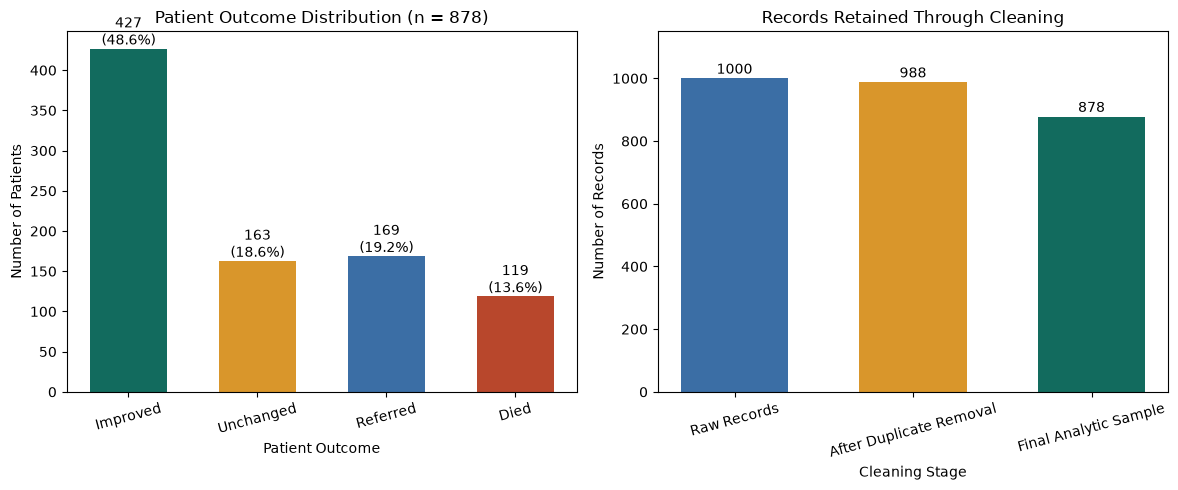

In [17]:
# ----- FIGURE 1: DATASET COMPOSITION -----

import matplotlib.pyplot as plt

# Arrange the patient outcomes in the required order.
outcome_order = ["Improved", "Unchanged", "Referred", "Died"]

counts = df["Patient_Outcome"].value_counts().reindex(
    outcome_order, fill_value=0
)

percentages = (counts / counts.sum()) * 100

colors = ["#126B5E", "#D9962B", "#3B6EA5", "#B8472C"]

# Create two charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Patient outcome distribution.
axes[0].bar(counts.index, counts.values, color=colors, width=0.6)

axes[0].set_title(f"Patient Outcome Distribution (n = {len(df)})")
axes[0].set_xlabel("Patient Outcome")
axes[0].set_ylabel("Number of Patients")
axes[0].tick_params(axis="x", rotation=15)

# Display the count and percentage above each bar.
for i, value in enumerate(counts.values):
    axes[0].text(
        i, value + 5,
        f"{value}\n({percentages.iloc[i]:.1f}%)",
        ha="center"
    )

# 2. Records retained through cleaning.
stages = ["Raw Records", "After Duplicate Removal", "Final Analytic Sample"]
records = [1000, 988, 878]

stage_colors = ["#3B6EA5", "#D9962B", "#126B5E"]

axes[1].bar(stages, records, color=stage_colors, width=0.6)

axes[1].set_title("Records Retained Through Cleaning")
axes[1].set_xlabel("Cleaning Stage")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=15)
axes[1].set_ylim(0, 1150)

# Display the number of records above each bar.
for i, value in enumerate(records):
    axes[1].text(i, value + 15, value, ha="center")

plt.tight_layout()
plt.show()

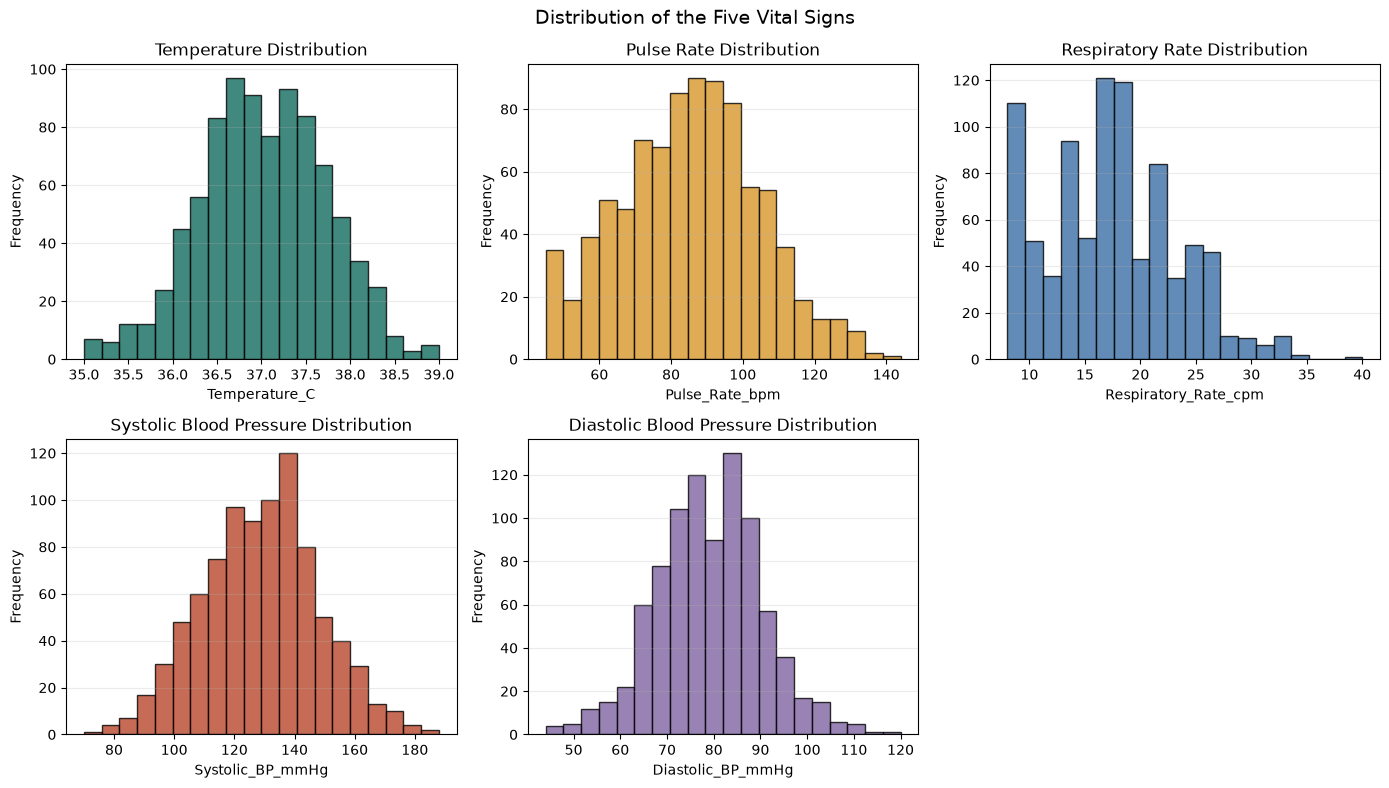

In [18]:
# ----- FIGURE 2: DISTRIBUTION OF VITAL SIGNS -----

# Select the five vital-sign variables.
vital_signs = [
    "Temperature_C",
    "Pulse_Rate_bpm",
    "Respiratory_Rate_cpm",
    "Systolic_BP_mmHg",
    "Diastolic_BP_mmHg"
]

titles = [
    "Temperature Distribution",
    "Pulse Rate Distribution",
    "Respiratory Rate Distribution",
    "Systolic Blood Pressure Distribution",
    "Diastolic Blood Pressure Distribution"
]

colors = ["#126B5E", "#D9962B", "#3B6EA5", "#B8472C", "#8064A2"]

# Create a 2-row, 3-column layout for the five histograms.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes = axes.flatten()

for i, variable in enumerate(vital_signs):

    # Plot the distribution of the current vital sign.
    axes[i].hist(
        df[variable].dropna(),
        bins=20,
        color=colors[i],
        edgecolor="black",
        alpha=0.8
    )

    axes[i].set_title(titles[i])
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.25)

# Remove the unused sixth plotting space.
axes[5].set_visible(False)

plt.suptitle("Distribution of the Five Vital Signs", fontsize=14)

plt.tight_layout()
plt.show()


## Part A: Statistical Associations (Objective 1)

### Section 1: Distribution and Assumption Checks

Before comparing vital signs across the four patient outcome groups, distribution and statistical assumption checks were performed to guide the selection of appropriate statistical tests.

For each vital sign, skewness and excess kurtosis were calculated to examine distribution shape. The Shapiro–Wilk test was used to assess normality within each outcome group, while median-centred Levene's test was used to assess equality of variances across the four groups.

These checks helped determine the suitability of classical one-way ANOVA and identify the need for alternative or robustness tests.


In [19]:
### --------------- RESULTS (PART A: SECTION 1) --------------- ###
### -------- DISTRIBUTION AND ASSUMPTION CHECKS -------- ###

from scipy.stats import shapiro, levene

# Loop through the five vital-sign variables
for col in ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]:

    # Display the name of the vital sign being analysed
    print("\n")
    print("=" * 65)
    print("DISTRIBUTION AND ASSUMPTION CHECKS:", col)
    print("=" * 65)

    # Calculate skewness and excess kurtosis for each patient outcome group
    table = pd.crosstab(index=df["Patient_Outcome"], values=df[col], columns="", aggfunc=["skew", "kurt"])

    # Display the distribution summary
    print("\n--- Distribution Summary: Skewness and Excess Kurtosis ---")
    print(table)

    # Separate vital-sign measurements according to patient outcome
    g1 = df.loc[df["Patient_Outcome"] == "Improved", col]
    g2 = df.loc[df["Patient_Outcome"] == "Died", col]
    g3 = df.loc[df["Patient_Outcome"] == "Referred", col]
    g4 = df.loc[df["Patient_Outcome"] == "Unchanged", col]

    # Perform Levene's test (median-centred) to assess equality of variances
    test = levene(g1, g2, g3, g4, center="median")

    # Perform Shapiro-Wilk tests to assess normality within each outcome group
    test1 = shapiro(g1)
    test2 = shapiro(g2)
    test3 = shapiro(g3)
    test4 = shapiro(g4)

    # Display Shapiro-Wilk test results for each patient outcome group
    print("\n--- Shapiro-Wilk Normality Test ---")
    print("-" * 65)
    print("Improved   | p-value:", test1.pvalue)
    print("Died       | p-value:", test2.pvalue)
    print("Referred   | p-value:", test3.pvalue)
    print("Unchanged  | p-value:", test4.pvalue)

    # Display Levene's test results for equality of variances
    print("\n--- Median-Centred Levene's Test ---")
    print("-" * 65)
    print("F-statistic:", test.statistic)
    print("P-value:   ", test.pvalue)

    # Display a separator before analysing the next vital sign
    print("\n" + "." * 65)



DISTRIBUTION AND ASSUMPTION CHECKS: Temperature_C

--- Distribution Summary: Skewness and Excess Kurtosis ---
                     skew      kurt
col_0                              
Patient_Outcome                    
Died            -0.022437  0.607772
Improved        -0.085339  0.018879
Referred        -0.044434 -0.582765
Unchanged        0.102527  0.195171

--- Shapiro-Wilk Normality Test ---
-----------------------------------------------------------------
Improved   | p-value: 0.08340495651802027
Died       | p-value: 0.6429307922861707
Referred   | p-value: 0.10096311327038393
Unchanged  | p-value: 0.727220201975749

--- Median-Centred Levene's Test ---
-----------------------------------------------------------------
F-statistic: 1.524174154750977
P-value:    0.206720958042894

.................................................................


DISTRIBUTION AND ASSUMPTION CHECKS: Pulse_Rate_bpm

--- Distribution Summary: Skewness and Excess Kurtosis ---
                     sk


### Section 2: Statistical Association with Effect Sizes

This section investigates whether the five vital signs (temperature, pulse rate, respiratory rate, systolic blood pressure and diastolic blood pressure) differ significantly across the four patient outcome groups: Improved, Unchanged, Referred and Died.

For each vital sign, descriptive statistics were calculated, including the sample size, mean, standard deviation, median and interquartile range.

Three statistical tests were performed to examine differences across the outcome groups:

- **One-way ANOVA:** Used to compare mean vital-sign measurements across the four outcome groups.
- **Welch ANOVA:** Used as a robustness test that does not assume equal variances.
- **Kruskal–Wallis test:** Used as a non-parametric alternative to compare distributions across the outcome groups.

Effect sizes were also calculated to assess the magnitude of the observed differences. Eta-squared (η²) and omega-squared (ω²) were calculated for standard one-way ANOVA, while epsilon-squared (ε²) was calculated for the Kruskal–Wallis test.

To account for multiple testing across the five primary one-way ANOVA tests, the Holm correction was applied to their p-values.

Finally, post-hoc pairwise comparisons were conducted to identify which specific patient outcome groups differed:

- **Tukey HSD:** Used for pairwise comparisons following standard one-way ANOVA. Mean differences, Cohen's d and Tukey-adjusted p-values were examined.
- **Dunn's test with Holm adjustment:** Used for rank-based pairwise comparisons following the Kruskal–Wallis test. Holm-adjusted p-values were used to account for the six pairwise comparisons within each vital sign.

These analyses provide information about the statistical significance, magnitude and direction of differences in vital signs across patient outcome groups.


In [20]:
### ----- RESULTS (PART A: SECTION 2): STATISTICAL ASSOCIATION WITH EFFECT SIZES ----- ###

# Import the additional libraries for multiple comparisons
import scikit_posthocs as sp
from statsmodels.stats.multitest import multipletests

# Store the five overall ANOVA p-values for Holm adjustment
anova_pvalues = []


##_______________ Vital Signs _______________##

for col in ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]:

    #_______________ Groups for Analysis _______________#

    print("\n")
    print(*"___"*3, col, "VS.", "Patient Outcome", *"___"*3)

    g1 = df.loc[df["Patient_Outcome"] == "Improved", col]
    g2 = df.loc[df["Patient_Outcome"] == "Died", col]
    g3 = df.loc[df["Patient_Outcome"] == "Referred", col]
    g4 = df.loc[df["Patient_Outcome"] == "Unchanged", col]

    groups = [g1, g2, g3, g4]


    #_______________ Descriptive Analysis _______________#

    table = pd.crosstab(
        index=df["Patient_Outcome"],
        values=df[col],
        columns="",
        aggfunc=["count", "mean", "std"]
    )

    print("\n--- Descriptive Statistics ---")
    print(table)
    print()

    for g in groups:
        Q1 = g.quantile(0.25)
        Q2 = g.quantile(0.5)
        Q3 = g.quantile(0.75)

        print("Median (IQR):", Q2, "(", Q1, "-", Q3, ")")


    #_______________ Sample Size and Number of Groups _______________#

    n = len(df)
    k = len(groups)


    #_______________ Hypothesis Testing _______________#

    from scipy.stats import f_oneway, kruskal
    import pingouin as pg

    # Standard one-way ANOVA
    result1 = f_oneway(g1, g2, g3, g4)

    # Welch ANOVA
    result2 = f_oneway(g1, g2, g3, g4, equal_var=False)

    # Kruskal-Wallis test
    result3 = kruskal(g1, g2, g3, g4)

    # Collect the standard ANOVA p-value for Holm adjustment
    anova_pvalues.append(result1.pvalue)


    #_______________ Degrees of Freedom _______________#

    # Standard one-way ANOVA
    dfb_standard = k - 1
    dfw_standard = n - k

    # Welch one-way ANOVA
    dfw_welch = pg.welch_anova(
        dv=col,
        between="Patient_Outcome",
        data=df
    ).loc[0, "ddof2"]

    dfb_welch = k - 1

    # Kruskal-Wallis
    df_kruskal = k - 1


    #_______________ Effect Sizes Analysis _______________#

    # Standard one-way ANOVA
    eta_sqrd = (result1.statistic * dfb_standard) / (
        (result1.statistic * dfb_standard) + dfw_standard
    )

    omega_sqrd = (dfb_standard * (result1.statistic - 1)) / (
        (dfb_standard * result1.statistic) + (dfw_standard + 1)
    )

    # Kruskal-Wallis
    elipson_sqrd = (result3.statistic - k + 1) / (n - k)


    #_______________ Overall Statistical Results _______________#

    print("\n")
    print("Results_________:")

    print(
        "Oneway ANOVA (Standard):",
        "F", "(", dfb_standard, ",", dfw_standard, ")",
        "=", result1.statistic.round(3),
        ", P-value =", result1.pvalue,
        ", Eta-squared =", eta_sqrd.round(3),
        ", Omega-squared =", omega_sqrd.round(3)
    )

    print(
        "Welch ANOVA:",
        "F", "(", dfb_welch, ",", dfw_welch.round(3), ")",
        "=", result2.statistic.round(3),
        ", P-value =", result2.pvalue
    )

    print(
        "Kruskal-Wallis test:",
        "H", "(", df_kruskal, ")",
        "=", result3.statistic.round(3),
        ", P-value =", result3.pvalue,
        ", Epsilon-squared =", elipson_sqrd
    )

    print("\n" + "+" * 65)


#_______________ Holm Adjustment Across Five Primary ANOVA Tests _______________#

# Apply Holm correction to the five standard ANOVA p-values
holm_results = multipletests(
    anova_pvalues,
    alpha=0.05,
    method="holm"
)

# Store the vital-sign names in the same order as the analysis
vital_signs = [
    "Temperature_C",
    "Pulse_Rate_bpm",
    "Respiratory_Rate_cpm",
    "Systolic_BP_mmHg",
    "Diastolic_BP_mmHg"
]

# Display the original and Holm-adjusted p-values
print("\n")
print("=" * 70)
print("HOLM-ADJUSTED P-VALUES ACROSS FIVE PRIMARY ANOVA TESTS")
print("=" * 70)

for col, original_p, adjusted_p in zip(
    vital_signs,
    anova_pvalues,
    holm_results[1]
):
    print("\nVital Sign:", col)
    print("Original p-value:", original_p)
    print("Holm-adjusted p-value:", adjusted_p)
    print("-" * 70)


#_______________ Post-Hoc Pairwise Comparisons _______________#

# Repeat the analysis for each vital sign to identify which outcome groups differ
for col in vital_signs:

    print("\n")
    print("=" * 70)
    print("POST-HOC PAIRWISE COMPARISONS:", col)
    print("=" * 70)

    # Tukey HSD: pairwise comparisons following standard one-way ANOVA
    tukey = pg.pairwise_tukey(
        data=df,
        dv=col,
        between="Patient_Outcome",
        effsize="cohen"
    )

    # Display the group comparisons, mean differences, Cohen's d and adjusted p-values
    print("\n--- Tukey HSD Pairwise Comparisons ---")
    print(
        tukey[["A", "B", "diff", "cohen", "p_tukey"]].round(4)
    )

    # Dunn's test: pairwise rank comparisons following Kruskal-Wallis
    # Holm adjustment is applied across the six outcome-group comparisons
    dunn = sp.posthoc_dunn(
        df,
        val_col=col,
        group_col="Patient_Outcome",
        p_adjust="holm"
    )

    # Display the Holm-adjusted Dunn pairwise p-values
    print("\n--- Dunn's Test (Holm-Adjusted P-values) ---")
    print(dunn.round(4))

    print("\n" + "+" * 70)




_ _ _ _ _ _ _ _ _ Temperature_C VS. Patient Outcome _ _ _ _ _ _ _ _ _

--- Descriptive Statistics ---
                count       mean       std
col_0                                     
Patient_Outcome                           
Died              119  37.495798  0.529374
Improved          427  36.609368  0.618233
Referred          169  37.443787  0.586434
Unchanged         163  37.081595  0.624227

Median (IQR): 36.6 ( 36.2 - 37.0 )
Median (IQR): 37.5 ( 37.2 - 37.8 )
Median (IQR): 37.4 ( 37.1 - 37.9 )
Median (IQR): 37.1 ( 36.7 - 37.5 )


Results_________:
Oneway ANOVA (Standard): F ( 3 , 874 ) = 118.032 , P-value = 3.5511228592201925e-64 , Eta-squared = 0.288 , Omega-squared = 0.286
Welch ANOVA: F ( 3 , 343.886 ) = 124.233 , P-value = 1.606308700846404e-54
Kruskal-Wallis test: H ( 3 ) = 261.243 , P-value = 2.4204859308785615e-56 , Epsilon-squared = 0.2954726253938592

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


_ _ _ _ _ _ _ _ _ Pulse_Rate_bpm VS. Patient Ou


### Correlation and Multicollinearity Assessment

This section examines the relationships among the five vital signs and assesses whether substantial multicollinearity exists between the variables.

**1. Pearson Correlation Analysis**

- Pearson correlation coefficients (r) were calculated for all 10 possible pairs of the five vital signs.
- The correlation coefficient measures the strength and direction of the linear relationship between two variables.
- Positive coefficients indicate that both variables tend to increase together, while negative coefficients indicate that one tends to decrease as the other increases.
- P-values were calculated to assess whether each observed correlation was statistically significant.

**2. Variance Inflation Factor (VIF)**

- VIF was calculated for each vital sign to assess how strongly it could be explained by the other four vital signs.
- Multiple linear regression was used to obtain the R-squared value for each variable.
- VIF was calculated using the formula:

  \[
  VIF = \frac{1}{1-R^2}
  \]

- Higher VIF values indicate greater multicollinearity, meaning that a predictor shares more linear information with the other predictors.
- VIF values were examined to determine whether multicollinearity was likely to be a concern for the subsequent predictive modelling.

**Purpose:** To understand the relationships among the vital signs and assess whether their correlations could introduce substantial multicollinearity into the predictive models.


In [21]:

# --------------- Correlation & Multicollinearity --------------- #

# Import the Pearson's correlation test 
from scipy.stats import pearsonr


# Calculate Pearson correlation coefficients and p-values for all
# 10 possible pairs of the five vital signs.

test1 = pearsonr(df["Temperature_C"], df["Pulse_Rate_bpm"]) 
test2 = pearsonr(df["Temperature_C"], df["Respiratory_Rate_cpm"])
test3 = pearsonr(df["Temperature_C"], df["Systolic_BP_mmHg"])
test4 = pearsonr(df["Temperature_C"], df["Diastolic_BP_mmHg"])
test5 = pearsonr(df["Pulse_Rate_bpm"], df["Respiratory_Rate_cpm"])
test6 = pearsonr(df["Pulse_Rate_bpm"], df["Systolic_BP_mmHg"])
test7 = pearsonr(df["Pulse_Rate_bpm"], df["Diastolic_BP_mmHg"])
test8 = pearsonr(df["Respiratory_Rate_cpm"], df["Systolic_BP_mmHg"])
test9 = pearsonr(df["Respiratory_Rate_cpm"], df["Diastolic_BP_mmHg"])
test10 = pearsonr(df["Systolic_BP_mmHg"], df["Diastolic_BP_mmHg"])


# Store each correlation result with its corresponding variable pair
tests = {
    "Temperature vs Pulse rate":        test1,
    "Temperature vs Respiratory rate":  test2,
    "Temperature vs Systolic BP":       test3,
    "Temperature vs Diastolic BP":      test4,
    "Pulse rate vs Respiratory rate":   test5,
    "Pulse rate vs Systolic BP":        test6,
    "Pulse rate vs Diastolic BP":       test7,
    "Respiratory rate vs Systolic BP":  test8,
    "Respiratory rate vs Diastolic BP": test9,
    "Systolic BP vs Diastolic BP":      test10,
}


# Organise the correlation coefficients and their p-values into a
# DataFrame for easier inspection and reporting.
result = pd.DataFrame({"Pair": list(tests),
              "Pearson r": [t.statistic for t in tests.values()],
              "p-value":   [t.pvalue for t in tests.values()]})

print("Correlation Coefficients with P-values...............")
print(result)


# --------------- Variance Inflation Factor (VIF) --------------- #

# Import LinearRegression to estimate how well each vital sign
# can be explained by the remaining vital signs.
from sklearn.linear_model import LinearRegression


# List the five vital signs included in the multicollinearity assessment.
V = ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm",
     "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]


# Calculate the VIF for each vital sign.
# Each variable is treated as the dependent variable and the other
# four vital signs are used as predictors.
vif = {}

for col in V:

    # Select all vital signs except the variable currently being assessed.
    others = [c for c in V if c != col]

    # Fit a multiple linear regression model and obtain its R-squared.
    # R-squared measures how much of the variable's variation is explained
    # by the other four vital signs.
    r2 = LinearRegression().fit(df[others], df[col]).score(df[others], df[col])

    # Calculate the Variance Inflation Factor.
    # Higher VIF values indicate greater multicollinearity.
    vif[col] = 1 / (1 - r2)          # VIF = 1 / (1 - R²)


# Display the calculated VIF values for all five vital signs.
print()
print("Variance Inflation Factors (VIF):...............")
print(pd.Series(vif).round(1))


Correlation Coefficients with P-values...............
                               Pair  Pearson r        p-value
0         Temperature vs Pulse rate   0.737736  1.209922e-151
1   Temperature vs Respiratory rate   0.713867  1.084392e-137
2        Temperature vs Systolic BP  -0.526774   7.605860e-64
3       Temperature vs Diastolic BP  -0.608334   5.438438e-90
4    Pulse rate vs Respiratory rate   0.775512  3.688526e-177
5         Pulse rate vs Systolic BP  -0.534807   4.131912e-66
6        Pulse rate vs Diastolic BP  -0.619586   3.228316e-94
7   Respiratory rate vs Systolic BP  -0.537440   7.248693e-67
8  Respiratory rate vs Diastolic BP  -0.617776   1.585883e-93
9       Systolic BP vs Diastolic BP   0.482825   1.801910e-52

Variance Inflation Factors (VIF):...............
Temperature_C           2.6
Pulse_Rate_bpm          3.2
Respiratory_Rate_cpm    3.0
Systolic_BP_mmHg        1.6
Diastolic_BP_mmHg       1.9
dtype: float64



### PART B: Predictive Performance (Objective 2)

This section develops and evaluates two multinomial logistic regression models to investigate whether the five vital signs can predict individual patient outcomes.

**1. Feature and Target Selection**

- The five vital signs were selected as predictor variables (X).
- Patient outcome was selected as the target variable (y).
- The four patient outcomes were numerically encoded in the following order: Improved, Unchanged, Referred and Died.

**2. Training and Test Data Split**

- The dataset was divided into 80% training data (702 patients) and 20% test data (176 patients).
- Stratified sampling preserved the distribution of patient outcomes in both sets.
- A fixed random state was applied to ensure reproducibility.

**3. Standardisation**

- StandardScaler was used to standardise the five vital signs.
- The scaler was fitted using the training data only.
- The same scaling parameters were applied to the test data to prevent data leakage.

**4. Baseline Model**

- A baseline model was established by assigning every test patient to the most common outcome, Improved.
- Its accuracy, macro precision, macro recall, macro F1 and macro AUC were calculated.
- This provided a reference point for assessing whether the logistic regression models performed better than always predicting the most frequent outcome.

**5. Plain Logistic Regression**

- A standard multinomial logistic regression model was trained using the standardised training data.
- Predictions and outcome probabilities were generated for the unseen test patients.
- Its confusion matrix, coefficients and outcome-specific evaluation metrics were examined.

**6. Balanced Logistic Regression**

- A second multinomial logistic regression model was trained using `class_weight="balanced"`.
- This setting automatically adjusts class weights to give greater consideration to less frequent outcomes.
- Its predictions and evaluation results were obtained using the same test patients.

**7. Model Evaluation**

Both logistic regression models were evaluated using:

- Accuracy: the overall proportion of correctly classified patients.
- Precision: the proportion of predicted patients in an outcome group who actually belonged to that group.
- Recall (sensitivity): the proportion of actual patients in an outcome group correctly identified.
- Specificity: the proportion of patients who did not belong to an outcome group and were correctly excluded from it.
- F1-score: the harmonic mean of precision and recall.
- AUC: measures the model's ability to distinguish each outcome from the remaining outcomes.

**8. Macro-Averaged Performance**

- Macro precision, macro recall, macro F1 and macro AUC were calculated for the baseline and both logistic regression models.
- Macro averaging gives equal importance to all four patient outcomes, regardless of their sample sizes.
- Macro recall is also known as balanced accuracy.

**9. ROC Curve Analysis**

- Four one-vs-rest ROC curves were generated for the balanced logistic regression model using the test-set predictions.
- Each curve evaluates the model's ability to distinguish one patient outcome from the other three.
- The area under each curve (AUC) was included to assess its ranking ability.

**Purpose:** To evaluate the predictive performance of the two logistic regression models against a simple baseline and examine how well the selected balanced model distinguishes the four patient outcomes.


Training Sets...............
Patient_Outcome
0    342
2    135
1    130
3     95
Name: count, dtype: int64

Testing Sets...............
Patient_Outcome
0    85
2    34
1    33
3    24
Name: count, dtype: int64

_______________ BASELINE MODEL _______________
Confusion Matrix...............
[[85  0  0  0]
 [33  0  0  0]
 [34  0  0  0]
 [24  0  0  0]]

Accuracy_Score: 0.48295454545454547
Macro Precision: 0.12073863636363637
Macro Recall:    0.25
Macro F1:        0.16283524904214558
Macro AUC:       0.5

_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ PLAIN LOGISTIC REGRESSION _ _ _ _ _ _ _ _ _ _ _ _ _ _ _
Confusion Matrix...............
[[72  2 10  1]
 [27  1  5  0]
 [14  3 11  6]
 [ 3  0 12  9]]

Coefficients...............
[[-0.32931898 -0.44942942 -0.69777243  0.21986758  0.1518148 ]
 [ 0.09824212  0.01270301 -0.38550306 -0.06700712  0.09702906]
 [ 0.24215573  0.21285059  0.36799794 -0.02504766 -0.11810786]
 [-0.01107886  0.22387582  0.71527755 -0.12781279 -0.13073601]]

Model Evaluation...............


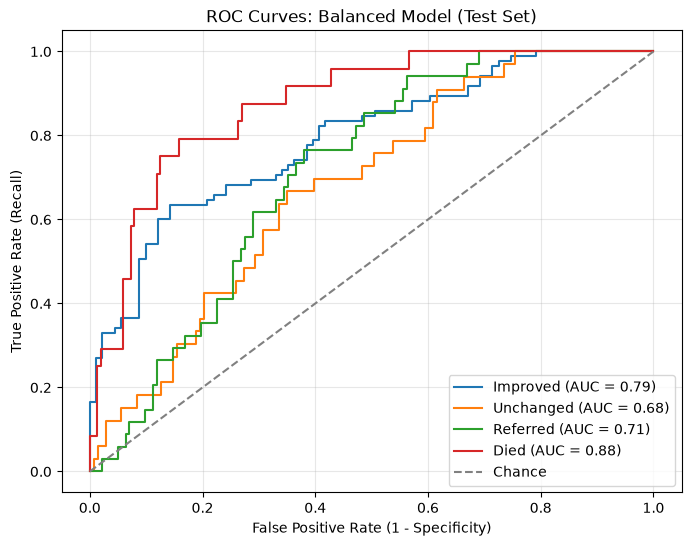

In [22]:
### ---------- PART B ---------- ###

## _______________ Importing Libraries _______________ ##

# Import LogisticRegression to build the predictive models.
from sklearn.linear_model import LogisticRegression

# Import train_test_split to divide the dataset into training and test sets.
from sklearn.model_selection import train_test_split

# Import StandardScaler and label_binarize for preprocessing.
from sklearn.preprocessing import StandardScaler, label_binarize

# Import evaluation metrics for assessing model performance.
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

# Import NumPy for numerical calculations.
import numpy as np

# Import Matplotlib for plotting ROC curves.
import matplotlib.pyplot as plt


## _______________ Patient's Outcomes Arrangement _______________ ##

# Define the order of patient outcomes.
# Each outcome will be represented by a numerical value:
# Improved = 0, Unchanged = 1, Referred = 2, Died = 3.
ORDER = ["Improved", "Unchanged", "Referred", "Died"]


## _______________ Features X's & Target y _______________ ##

# Select the five vital signs as predictor variables (X).
X = df[["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm",
        "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]]

# Convert the categorical patient outcomes into numerical values (y)
# using the previously defined outcome order.
y = df["Patient_Outcome"].map({o: i for i, o in enumerate(ORDER)})


## _______________ Splitting Data ____________________ ##

# Split the dataset into 80% training data and 20% test data.
# Stratification preserves the proportion of each patient outcome
# in both sets, while random_state ensures reproducibility.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=20261114
)


## ________________ Standardizing X's Values _______________ ##

# Create a scaler to standardise the five vital signs.
scaler = StandardScaler()

# Calculate the means and standard deviations from the training data
# and use them to standardise the training predictors.
X_train_s = scaler.fit_transform(X_train)

# Apply the same training-set scaling parameters to the test predictors.
# This prevents information from the test set leaking into training.
X_test_s = scaler.transform(X_test)


##_______________ Sample Design _______________##

# Display the number of patients belonging to each outcome
# in the training and test sets.
print("Training Sets...............")
print(y_train.value_counts())
print()

print("Testing Sets...............")
print(y_test.value_counts())
print()


##_______________ Baseline Model _______________##

# Store the actual outcomes of the test patients.
y_actual = y_test.values

# Create a baseline prediction that assigns every test patient
# to the most common outcome: Improved (class 0).
baseline_pred = np.zeros(len(y_actual), dtype=int)

# Create constant baseline scores for the four outcomes.
# Every patient receives a score of 1 for Improved and 0 for the others.
baseline_prob = np.zeros((len(y_actual), len(ORDER)))
baseline_prob[:, 0] = 1

print("___"*5, "BASELINE MODEL", "___"*5)

# Display the baseline confusion matrix.
print("Confusion Matrix...............")
cm = confusion_matrix(y_actual, baseline_pred, labels=[0, 1, 2, 3])
print(cm)
print()

# Calculate the baseline accuracy.
print("Accuracy_Score:", accuracy_score(y_actual, baseline_pred))

# Calculate macro precision, recall and F1-score.
# Macro averaging gives equal weight to all four patient outcomes.
print("Macro Precision:", precision_score(
    y_actual, baseline_pred, average="macro", zero_division=0
))

print("Macro Recall:   ", recall_score(
    y_actual, baseline_pred, average="macro", zero_division=0
))

print("Macro F1:       ", f1_score(
    y_actual, baseline_pred, average="macro", zero_division=0
))

# Calculate the baseline macro AUC using one-vs-rest classification.
print("Macro AUC:      ", roc_auc_score(
    y_actual, baseline_prob, multi_class="ovr", average="macro"
))
print()


##_______________ Plain Logistic Regression _______________##
#-----------------------------------------------------------#

# Display a heading for the first predictive model.
print(*"___"*5, "PLAIN LOGISTIC REGRESSION", *"___"*5)

# Create and train a standard multinomial logistic regression model
# using the standardised training predictors and their outcomes.
# max_iter=2000 allows sufficient iterations for model convergence.
plain_model = LogisticRegression(max_iter=2000)
plain_model.fit(X_train_s, y_train)

# Predict the most likely outcome for each test patient.
y_predicted = plain_model.predict(X_test_s)

# Obtain the predicted probability of belonging to each outcome.
y_prob = plain_model.predict_proba(X_test_s)

# Preserve the plain model's predicted probabilities for later use.
plain_prob = y_prob


# Display the confusion matrix.
# Rows represent actual outcomes and columns represent predicted outcomes.
print("Confusion Matrix...............")
cm = confusion_matrix(y_actual, y_predicted, labels=[0, 1, 2, 3])
print(cm)
print()


# Display the model coefficients.
# Rows correspond to patient outcomes, while columns correspond
# to the five standardised vital signs in the order defined in X.
print("Coefficients...............")
print(plain_model.coef_)
print()


# Evaluate the model using the unseen test patients.
print("Model Evaluation...............")

# Calculate the proportion of all test patients correctly classified.
print("Accuracy_Score: ", accuracy_score(y_actual, y_predicted))

# Display the outcome order for interpreting the metric arrays below.
print("Patient Outcome:", ORDER)

# Calculate precision separately for each patient outcome.
print("precision_Score:", precision_score(
    y_actual, y_predicted, average=None, zero_division=0
))

# Calculate recall (sensitivity) separately for each patient outcome.
print("Recall_Score:   ", recall_score(
    y_actual, y_predicted, average=None, zero_division=0
))

# Calculate the F1-score separately for each patient outcome.
print("F1_Score:       ", f1_score(
    y_actual, y_predicted, average=None, zero_division=0
))

# Calculate one-vs-rest AUC separately for each patient outcome.
print("AUC_Score:      ", roc_auc_score(
    y_actual, plain_prob, multi_class="ovr", average=None
))
print()


# Calculate macro-averaged performance scores.
# Each of the four patient outcomes contributes equally to the average.
print("Macro Evaluation...............")

print("Macro Precision:", precision_score(
    y_actual, y_predicted, average="macro", zero_division=0
))

print("Macro Recall:   ", recall_score(
    y_actual, y_predicted, average="macro", zero_division=0
))

print("Macro F1:       ", f1_score(
    y_actual, y_predicted, average="macro", zero_division=0
))

print("Macro AUC:      ", roc_auc_score(
    y_actual, plain_prob, multi_class="ovr", average="macro"
))
print()


# Calculate specificity separately for each patient outcome.
# Specificity measures the proportion of patients without an outcome
# who are correctly classified as not belonging to that outcome.
print("Specificity...............")

specificity = []

for i in range(len(ORDER)):

    tn = np.sum((y_actual != i) & (y_predicted != i))
    fp = np.sum((y_actual != i) & (y_predicted == i))

    specificity.append(tn / (tn + fp))

print(specificity)
print()


##_______________ Balanced Logistic Regression _______________##
#--------------------------------------------------------------#

# Display a heading for the second predictive model.
print(*"___"*5, "BALANCED LOGISTIC REGRESSION", *"___"*5)

# Create a logistic regression model with class weighting.
# class_weight="balanced" gives greater weight to less frequent outcomes
# to help the model account for the unequal outcome distribution.
balanced_model = LogisticRegression(
    max_iter=2000, class_weight="balanced"
)

# Train the balanced model using the same training data.
balanced_model.fit(X_train_s, y_train)

# Predict the most likely outcome for each test patient.
y_predicted = balanced_model.predict(X_test_s)

# Obtain the predicted probability of belonging to each outcome.
y_prob = balanced_model.predict_proba(X_test_s)

# Preserve the balanced model's predicted probabilities for later use.
balanced_prob = y_prob


# Display the confusion matrix.
print("Confusion Matrix...............")
cm = confusion_matrix(y_actual, y_predicted, labels=[0, 1, 2, 3])
print(cm)
print()


# Display the coefficients of the balanced model.
print("Coefficients...............")
print(balanced_model.coef_)
print()


# Evaluate the balanced model using the unseen test patients.
print("Model Evaluation...............")

# Calculate the proportion of all test patients correctly classified.
print("Accuracy_Score: ", accuracy_score(y_actual, y_predicted))

# Display the outcome order for interpreting the metric arrays below.
print("Patient Outcome:", ORDER)

# Calculate precision separately for each patient outcome.
print("precision_Score:", precision_score(
    y_actual, y_predicted, average=None, zero_division=0
))

# Calculate recall (sensitivity) separately for each patient outcome.
print("Recall_Score:   ", recall_score(
    y_actual, y_predicted, average=None, zero_division=0
))

# Calculate the F1-score separately for each patient outcome.
print("F1_Score:       ", f1_score(
    y_actual, y_predicted, average=None, zero_division=0
))

# Calculate one-vs-rest AUC separately for each patient outcome.
print("AUC_Score:      ", roc_auc_score(
    y_actual, balanced_prob, multi_class="ovr", average=None
))
print()


# Calculate macro-averaged performance scores.
print("Macro Evaluation...............")

print("Macro Precision:", precision_score(
    y_actual, y_predicted, average="macro", zero_division=0
))

print("Macro Recall:   ", recall_score(
    y_actual, y_predicted, average="macro", zero_division=0
))

print("Macro F1:       ", f1_score(
    y_actual, y_predicted, average="macro", zero_division=0
))

print("Macro AUC:      ", roc_auc_score(
    y_actual, balanced_prob, multi_class="ovr", average="macro"
))
print()


# Calculate specificity separately for each patient outcome.
print("Specificity...............")

specificity = []

for i in range(len(ORDER)):

    tn = np.sum((y_actual != i) & (y_predicted != i))
    fp = np.sum((y_actual != i) & (y_predicted == i))

    specificity.append(tn / (tn + fp))

print(specificity)
print()


##_______________ ROC Curves: Balanced Model _______________##
#------------------------------------------------------------#

# Convert the actual test outcomes into binary columns.
# Each column represents one outcome against all remaining outcomes.
y_test_bin = label_binarize(y_actual, classes=[0, 1, 2, 3])

# Create a figure for the four one-vs-rest ROC curves.
plt.figure(figsize=(8, 6))

for i, outcome in enumerate(ORDER):

    # Calculate the false-positive and true-positive rates
    # using the balanced model's predicted probabilities.
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i], balanced_prob[:, i]
    )

    # Obtain the AUC for the current patient outcome.
    auc_value = roc_auc_score(
        y_test_bin[:, i], balanced_prob[:, i]
    )

    # Plot the ROC curve and include its AUC in the legend.
    plt.plot(
        fpr, tpr,
        label=f"{outcome} (AUC = {auc_value:.2f})"
    )


# Add the diagonal reference line representing chance-level discrimination.
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")

# Label the axes and add a title.
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves: Balanced Model (Test Set)")

# Display the legend and grid.
plt.legend()
plt.grid(alpha=0.3)

# Display the ROC curves.
plt.show()


### 11. Part C: Predictive Sufficiency (Objective 3)
This section evaluates whether the balanced logistic regression model meets the three predefined predictive sufficiency criteria using the results obtained in Part B.
- Overall model performance: Macro-F1 must be at least 0.70.
- Performance across outcomes: Recall must be at least 60% for all four patient outcomes.
- Improvement over baseline: The lower limit of the model's 95% Wilson confidence interval for accuracy must be greater than the baseline accuracy.
The 95% Wilson confidence interval is calculated using the model's accuracy and the number of test patients.

Purpose: To determine whether the five vital signs alone provide sufficient predictive performance for distinguishing the four patient outcomes.

#### Note: The metric values used in this assessment are carried over from the Part B results.

In [23]:
# Part C: Predictive Sufficiency Assessment

# Existing results from Part B
macro_f1 = 0.4592013889
outcome_recall = [0.67058824, 0.45454545, 0.14705882, 0.70833333]

balanced_accuracy = 0.5340909091
baseline_accuracy = 0.4829545455

# Calculate the 95% Wilson confidence interval for accuracy
n = len(y_actual)
z = 1.96
p = balanced_accuracy

denominator = 1 + z**2 / n

center = (p + z**2 / (2 * n)) / denominator
margin = z * np.sqrt(
    (p * (1 - p) / n) + z**2 / (4 * n**2)
) / denominator

lower_limit = center - margin
upper_limit = center + margin

# Assess the three predefined criteria
print("PREDICTIVE SUFFICIENCY ASSESSMENT")
print("--------------------------------")

print("Macro-F1 >= 0.70:", macro_f1 >= 0.70)

print("Recall >= 0.60 for all outcomes:",
      all(value >= 0.60 for value in outcome_recall))

print("Lower accuracy limit > baseline:",
      lower_limit > baseline_accuracy)

print("\n95% Accuracy Confidence Interval:",
      round(lower_limit, 3), "-", round(upper_limit, 3))

PREDICTIVE SUFFICIENCY ASSESSMENT
--------------------------------
Macro-F1 >= 0.70: False
Recall >= 0.60 for all outcomes: False
Lower accuracy limit > baseline: False

95% Accuracy Confidence Interval: 0.46 - 0.606


**Exporting the Cleaned Dataset**

The cleaned dataset was exported to an Excel workbook and included in the project repository on GitHub. This allows any visitor to access and download the cleaned dataset alongside the original dataset, project report, and analysis notebook.

In [24]:
# Export the cleaned dataset to an Excel file.
# index=False prevents pandas from adding the DataFrame index as an extra column.
df.to_excel("Cleaned_Vital_Signs_Analysis_Dataset.xlsx", index=False)

# Confirm that the export command has completed.
print("File Saved Successfully..........")

File Saved Successfully..........
